# IND320 Project part 4

Niclas

GitHub repository: https://github.com/karlsenniclas-ops/IND320-project

Streamlit app: https://ind320-project-niclas.streamlit.app

The work for this part was done on the `part4` branch and merged into `main` after the peer review and feedback on part 3.

## Log

In part 4 I added exchange rates from Norges Bank, checked the time zones of the data sources, made a reservoir forecast with River, and reorganised the Streamlit app with Plotly, a map and two new pages. The feedback from the TA and the peer review on part 3 is fixed, so this part builds on the corrected version.

The Norges Bank API was easy to read with format=csv. The magasinstatistikk and Norges Bank only have Norwegian dates, ENTSO-E is in UTC, and open-meteo is in GMT unless timezone is set. With timezone=Europe/Oslo open-meteo uses one offset for the whole request, so summer time is ignored. For weekly data that is only one hour, so I use daily weather with that setting and sum it to the same weeks as the magasinstatistikk.

For the forecast I used SNARIMAX from River with weekly data, since the filling is weekly and hourly weather would take long to download and give very long series. In the backtests the seasonal differencing mattered most, and (1,1,1)(1,1,1) with 5 years of history was best. Precipitation helped, but only because the real future precipitation was used, so the default has no exogenous variables.

Before changing the app I made the sketch above and grouped the pages into overview, exploratory, anomalies and predictive, with a coloured label for the active group and a blue theme. All matplotlib plots are now Plotly. I joined the LineChartColumn table with the reservoir plot on a data overview page instead of removing it. The map follows the folium choropleth example from the lecture, where a click gives the area a red outline and saves it in the session state for the other pages. The week on the map is also the end of the training data on the forecasting page. Streamlit removes widget values when a page without the widget is shown, so the shared selections are written back to the session state on every run. Lines made with Plotly's graph_objects did not get the theme colours, so they get the theme colour directly.

On the sliding window correlation page I compared the weather with the weekly change in filling for EL 3. With a 13-week window, temperature correlates strongly from November to May (about 0,7-0,8), when mild weeks give rain and snowmelt, but is around zero or slightly negative in July and August. Precipitation correlates well from August to February, but hardly in spring and early summer when snowmelt decides. Snowfall lagged about 20 weeks correlates positively (about 0,5), since the snow fills the reservoirs when it melts. Correlations that change with the season can explain why precipitation only helped a little in SNARIMAX, and lagged snowfall could be worth testing in the forecast.

For the bonus I chose waiting time: spinners while data is downloaded and the model is trained, and caching of the downloads, the GeoJSON files and all the calculations.

## AI usage

I used Claude as help during this part, mostly for the map with clicks, keeping the selections between pages in the session state, and setting up the backtests of the River model. It also helped me find out how open-meteo handles the timezone setting. I ran the notebook and the app myself and checked that the outputs and plots made sense before handing it in.

## Imports

In [1]:
# Packages used in this notebook (new in part 4: pip install river)
%matplotlib inline
import io
import os
import time
import tomllib
import xml.etree.ElementTree as ET

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from river import time_series

## Sketch of the app

Before changing the code I sketched the pages and how the selections should go between them. The pages are grouped by the type of task: overview, exploratory, anomalies and predictive. The shared selections (area, period, weather property and week) are kept in the session state, so a choice on one page is used on the others. A click on the map chooses the area for the other pages, and the week on the map is the end of the training data on the forecasting page.

The LineChartColumn table is joined with the reservoir plot into one data overview page with two tabs.

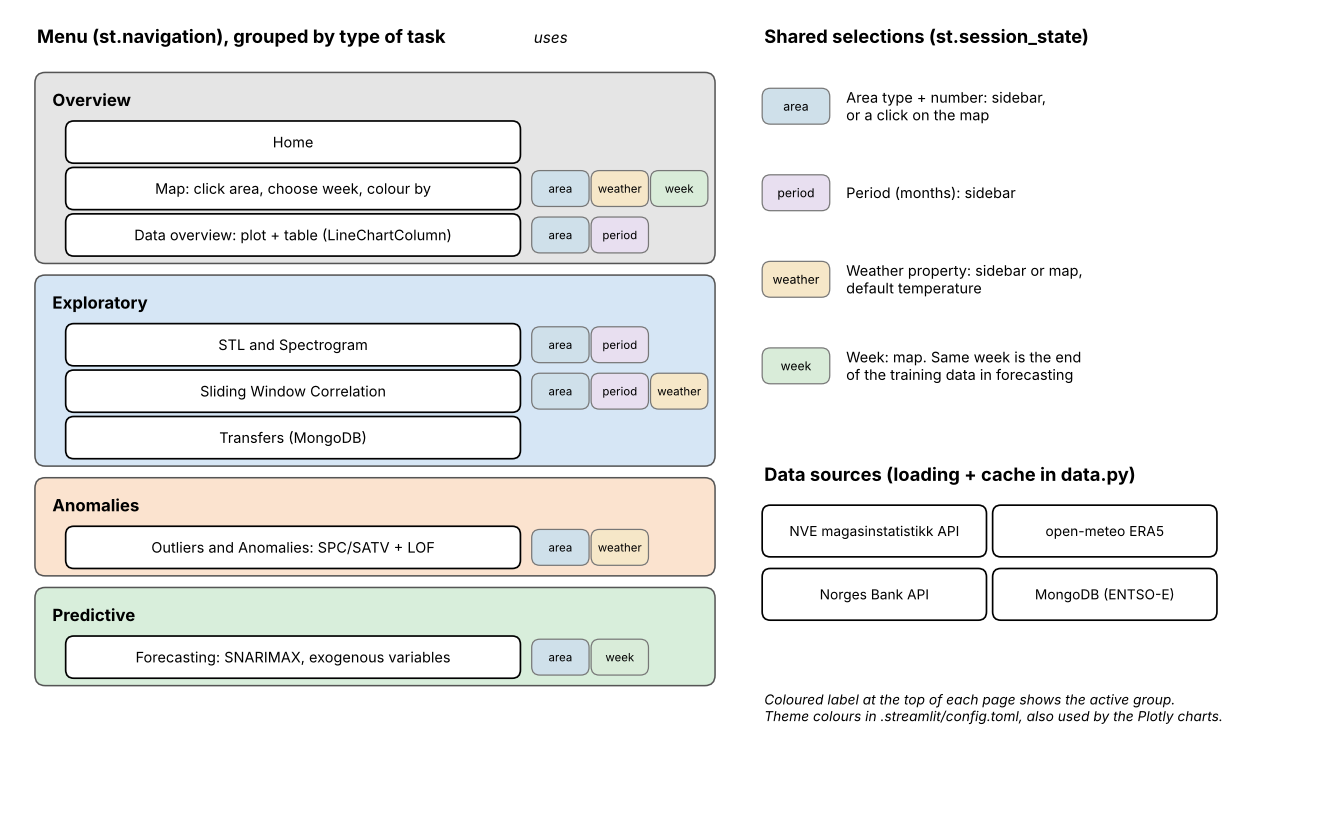

## Exchange rates from Norges Bank

Norges Bank has an open API for exchange rates. The URL has the frequency (B for business days), the currencies, the quote currency (NOK) and the type of rate (SP for spot). With `format=csv` the answer can be read with pandas. The same function is in `currency.py`, which the Streamlit app uses.

In [2]:
# Norges Bank's exchange rate API. B is business days, NOK is the quote currency
# and SP is the spot rate
NB_URL = "https://data.norges-bank.no/api/data/EXR/B.{}.NOK.SP"


def download_exchange_rates(start, end, currencies=("EUR", "USD")):
    """Daily exchange rates from Norges Bank, as NOK per unit of each currency.

    start and end are dates like "2024-01-01". There is only a rate on business
    days.
    """
    # Several currencies are joined with + in the URL, e.g. B.EUR+USD.NOK.SP
    url = NB_URL.format("+".join(currencies))
    params = {"format": "csv", "startPeriod": start, "endPeriod": end,
              "locale": "en"}
    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()

    # The CSV has one row per currency and day, with the rate in OBS_VALUE
    df = pd.read_csv(io.StringIO(response.text), sep=";")
    rates = df.pivot(index="TIME_PERIOD", columns="BASE_CUR", values="OBS_VALUE")
    rates.index = pd.to_datetime(rates.index).rename("date")
    rates.columns.name = None
    return rates

In [3]:
# Test for 2024
rates = download_exchange_rates("2024-01-01", "2024-12-31")
print(len(rates), "business days")
rates.head()

251 business days


,EUR,USD
date,,
2024-01-02,11.2815,10.2971
2024-01-03,11.3200,10.3672
2024-01-04,11.2845,10.3027
2024-01-05,11.3090,10.3553
2024-01-08,11.3620,10.3800


## Time zones

Before combining the sources I checked what the time stamps in each of them mean.

### Magasinstatistikk

In [4]:
# All reservoir data from the NVE API, as in part 2 and 3
NVE_URL = ("https://biapi.nve.no/magasinstatistikk/api/"
           "Magasinstatistikk/HentOffentligData")
reservoirs = pd.DataFrame(requests.get(NVE_URL, timeout=60).json())
reservoirs["dato_Id"] = pd.to_datetime(reservoirs["dato_Id"])

# Weekday of the dates, and the newest rows with ISO week
# and the time of the next publication
print(reservoirs["dato_Id"].dt.day_name().value_counts())
reservoirs.sort_values("dato_Id")[["dato_Id", "iso_aar", "iso_uke",
                                   "neste_Publiseringsdato"]].tail(3)

dato_Id
Sunday    14958
Name: count, dtype: int64


,dato_Id,iso_aar,iso_uke,neste_Publiseringsdato
8307,2026-11-08,2026,45,2026-11-18T13:00:00
8309,2026-11-08,2026,45,2026-11-18T13:00:00
14957,2026-11-08,2026,45,2026-11-18T13:00:00


All dates are Sundays, the last day of the ISO week, and there is no time of day. The degree of filling is given for the end of each week, in Norwegian dates. The time of the next publication (Wednesday 13:00) has no time zone either, so it is Norwegian time. There is nothing to convert here, but the other sources have to be summed over the same weeks, Monday to Sunday in Norwegian time.

### ENTSO-E

In [5]:
# The ENTSO-E token is in the same secrets file as the app uses (not on GitHub)
with open("../.streamlit/secrets.toml", "rb") as f:
    secrets = tomllib.load(f)

# Flow from NO1 to SE3 for the Norwegian day 1 June 2024. The API wants the times
# in UTC, and Norway is UTC+2 in summer
params = {
    "securityToken": secrets["entsoe"]["token"],
    "documentType": "A11",
    "out_Domain": "10YNO-1--------2",  # NO1
    "in_Domain": "10Y1001A1001A46L",  # SE3
    "periodStart": "202405312200",
    "periodEnd": "202406012200",
}
response = requests.get("https://web-api.tp.entsoe.eu/api", params=params,
                        timeout=60)
root = ET.fromstring(response.content)

# Start and end of the period in the answer, and the start in Norwegian time
start = root.find(".//{*}Period/{*}timeInterval/{*}start").text
end = root.find(".//{*}Period/{*}timeInterval/{*}end").text
print("Start:", start, " End:", end)
print("Start in Norwegian time:", pd.Timestamp(start).tz_convert("Europe/Oslo"))

Start: 2024-05-31T22:00Z  End: 2024-06-01T22:00Z
Start in Norwegian time: 2024-06-01 00:00:00+02:00


ENTSO-E gives all times in UTC (the Z at the end). To get the Norwegian day I had to ask from 22:00 UTC the day before. In part 2 the flows were summed per UTC day before they went to MongoDB, so a day on the Transfers page starts at 01:00 (winter) or 02:00 (summer) Norwegian time. The solution is to convert the times with `tz_convert("Europe/Oslo")` before grouping by date.

### open-meteo

In [6]:
# open-meteo's historical weather API (ERA5), as in part 3
ERA5_URL = "https://archive-api.open-meteo.com/v1/archive"

# One location near Trondheim around the change to summer time (31 March 2024),
# first with the default time zone (GMT) and then with timezone=Europe/Oslo
temps = {}
for tz in ["GMT", "Europe/Oslo"]:
    params = {"latitude": 63.43, "longitude": 10.4,
              "start_date": "2024-03-30", "end_date": "2024-04-01",
              "hourly": "temperature_2m", "models": "era5", "timezone": tz}
    answer = requests.get(ERA5_URL, params=params, timeout=60).json()
    temps[tz] = pd.Series(answer["hourly"]["temperature_2m"],
                          index=pd.to_datetime(answer["hourly"]["time"]))
    print(tz, " utc_offset_seconds:", answer["utc_offset_seconds"],
          " hours:", len(temps[tz]))

GMT  utc_offset_seconds: 0  hours: 72
Europe/Oslo  utc_offset_seconds: 3600  hours: 72


In [7]:
# With summer time, 12:00 in Norway on 1 April is 10:00 UTC.
# The Europe/Oslo value is the GMT value from 11:00
t = pd.Timestamp("2024-04-01 12:00")
print("Europe/Oslo 12:00:", temps["Europe/Oslo"][t])
print("GMT 10:00:", temps["GMT"][t - pd.Timedelta(hours=2)])
print("GMT 11:00:", temps["GMT"][t - pd.Timedelta(hours=1)])

Europe/Oslo 12:00: 5.9
GMT 10:00: 5.5
GMT 11:00: 5.9


By default open-meteo uses GMT (UTC), which is what the hourly data in part 3 has. With `timezone=Europe/Oslo` the times are moved to Norwegian time, but with one fixed offset for the whole request (3600 seconds). There are 72 hours and 02:00 on 31 March is not skipped, so after the change to summer time the times are one hour behind the real Norwegian time. For daily and weekly sums this only moves one hour per day in summer, so I use `timezone=Europe/Oslo` for the daily weather below. When the exact hour matters it is better to download in GMT and convert with pandas, which handles summer time.

### Norges Bank

In [8]:
# EUR around Easter 2024 (28 March to 1 April were holidays),
# with the column that says when the rate is set
params = {"format": "csv", "startPeriod": "2024-03-25", "endPeriod": "2024-04-07",
          "locale": "en"}
response = requests.get(NB_URL.format("EUR"), params=params, timeout=60)
nb = pd.read_csv(io.StringIO(response.text), sep=";")
nb["weekday"] = pd.to_datetime(nb["TIME_PERIOD"]).dt.day_name()
nb[["TIME_PERIOD", "weekday", "OBS_VALUE", "Collection Indicator"]]

,TIME_PERIOD,weekday,OBS_VALUE,Collection Indicator
0,2024-03-25,Monday,11.6050,ECB concertation time 14:15 CET
1,2024-03-26,Tuesday,11.6260,ECB concertation time 14:15 CET
2,2024-03-27,Wednesday,11.6825,ECB concertation time 14:15 CET
3,2024-04-02,Tuesday,11.7080,ECB concertation time 14:15 CET
4,2024-04-03,Wednesday,11.6580,ECB concertation time 14:15 CET
5,2024-04-04,Thursday,11.6125,ECB concertation time 14:15 CET
6,2024-04-05,Friday,11.6118,ECB concertation time 14:15 CET


Norges Bank gives dates only, and the rate is the one at 14:15 Central European Time, which is the same as Norwegian time. There are no rates on weekends and holidays. So there is no time zone problem, but the missing days have to be handled. I use the mean of the business days in each week, which gives a value for every week.

### Summary

| Source | Time in the data | Solution |
|---|---|---|
| Magasinstatistikk | Dates (Sundays), Norwegian time | Used as the weeks for everything else |
| ENTSO-E | UTC | `tz_convert("Europe/Oslo")` before summing per day |
| open-meteo | GMT by default, fixed offset with `timezone` | Daily values with `timezone=Europe/Oslo`, summed per week |
| Norges Bank | Dates, rate at 14:15 CET, business days only | Mean per week |

The differences are at most two hours. For weekly data this hardly matters, but for hourly and daily data from ENTSO-E and open-meteo it has to be handled. In pandas the weeks ending on Sunday are `resample("W-SUN")`, which gives the same dates as the magasinstatistikk.

## Areas as GeoJSON

The map in the app uses GeoJSON, so the shapefiles from part 3 are converted. The area numbers from the magasinstatistikk are added, and the water areas are joined from NVE's regions like in part 3 (VASS 1 = RS + RØ, VASS 2 = RV, VASS 3 = RM + RN).

In [9]:
# Shapefiles from part 3
price_areas = gpd.read_file("../data/shapefiles/price_areas.shp")
nve_regions = gpd.read_file("../data/shapefiles/nve_regions.shp")

# Area numbers as in the magasinstatistikk: "NO 1" to "NO 5" are EL 1-5,
# and the regions are joined into VASS 1-3
price_areas["area_number"] = price_areas["budomr"].str[-1].astype(int)
nve_regions["area_number"] = nve_regions["REGION"].map({"RS": 1, "RØ": 1, "RV": 2,
                                                        "RM": 3, "RN": 3})
water_areas = nve_regions.dissolve(by="area_number").reset_index()

# Save as GeoJSON for the map in the app
os.makedirs("../data/geojson", exist_ok=True)
price_areas[["area_number", "geometry"]].to_file(
    "../data/geojson/price_areas.geojson", driver="GeoJSON")
water_areas[["area_number", "geometry"]].to_file(
    "../data/geojson/water_areas.geojson", driver="GeoJSON")
print(len(price_areas), "price areas and", len(water_areas), "water areas saved")

5 price areas and 3 water areas saved


## Forecasting the degree of filling with River

### Time resolution

The degree of filling is only given once a week, so the forecast has to be weekly or coarser. The hourly weather from part 3 would give 8760 steps per year and a season length of 8760 in SNARIMAX, compared to 52 for weekly data. Downloading it is also slow, since 200 locations for one year in NO3 is about 1500 of the 10 000 free API calls per day.

So I use weekly data. The weather is downloaded as daily values (open-meteo's daily mean or sum) and summed to the same weeks as the magasinstatistikk. To keep the number of API calls down I use 10 of the 1000 locations sampled in part 3, which is about 100 calls for one area and one year. The exchange rates are averaged per week. A monthly model is tested below to compare.

In [10]:
# The locations sampled in part 3
POINTS_FILE = "../data/region_points.csv"

# Daily properties from open-meteo,
# renamed to the names of the hourly properties in part 3
DAILY_VARIABLES = {
    "temperature_2m_mean": "temperature_2m",
    "precipitation_sum": "precipitation",
    "snowfall_sum": "snowfall",
    "wind_speed_10m_mean": "wind_speed_10m",
}


def download_daily(region, start, end, n_points=10, points_file=POINTS_FILE):
    """Daily ERA5 weather for a region, averaged over the first n_points sampled
    locations.

    Same grid cell weighting as download_era5 in part 3, but with daily values.
    timezone=Europe/Oslo gives Norwegian days, so the days can be summed to the
    same weeks as in the magasinstatistikk.
    """
    points = pd.read_csv(points_file)
    points = points[points["region"] == region].head(n_points)

    # Round the locations to the nearest grid cell and count the locations
    # in each cell
    cells = (points[["lat", "lon"]] / 0.25).round() * 0.25
    cells = cells.value_counts().reset_index()

    params = {
        "latitude": ",".join(cells["lat"].astype(str)),
        "longitude": ",".join(cells["lon"].astype(str)),
        "start_date": start,
        "end_date": end,
        "daily": ",".join(DAILY_VARIABLES),
        "models": "era5",
        "wind_speed_unit": "ms",
        "timezone": "Europe/Oslo",
    }
    response = requests.get(ERA5_URL, params=params, timeout=120)
    response.raise_for_status()
    locations = response.json()
    if isinstance(locations, dict):  # a single location is not returned as a list
        locations = [locations]

    # Add the daily values of each cell, weighted by the number of locations
    # in the cell
    total = 0
    for location, count in zip(locations, cells["count"]):
        daily = pd.DataFrame(location["daily"]).set_index("time")
        total = total + daily * count

    weather = total / cells["count"].sum()
    weather.index = pd.to_datetime(weather.index)
    return weather.rename(columns=DAILY_VARIABLES)


def to_weekly(daily):
    """Weekly weather for weeks ending on Sunday, like the dates in the
    magasinstatistikk.

    Temperature and wind speed are averaged and precipitation and snowfall are
    summed. Weeks that do not have values for all seven days (ERA5 is about 5
    days behind) are left out.
    """
    daily = daily.dropna()
    weekly = daily.resample("W-SUN").agg({
        "temperature_2m": "mean",
        "precipitation": "sum",
        "snowfall": "sum",
        "wind_speed_10m": "mean",
    })
    days = daily["temperature_2m"].resample("W-SUN").count()
    return weekly[days == 7]

### Weekly data for EL 3

EL 3 (NO3) is used for the tests, the same area as in part 3. The daily weather for 2014-2025 is saved to a file, so it is only downloaded the first time the notebook is run.

In [11]:
# Daily weather for NO3, read from the file if it is there
WEATHER_FILE = "../data/era5_daily_NO3_2014_2025.csv"
if os.path.exists(WEATHER_FILE):
    daily = pd.read_csv(WEATHER_FILE, index_col="time", parse_dates=True)
else:
    daily = download_daily("NO3", "2014-01-01", "2025-12-31")
    daily.to_csv(WEATHER_FILE)

weekly_weather = to_weekly(daily)
weekly_weather.head()

,temperature_2m,precipitation,snowfall,wind_speed_10m
time,,,,
2014-01-12,-1.404286,10.65,3.164,3.807571
2014-01-19,-5.304286,0.95,1.078,6.191571
2014-01-26,-4.098571,0.60,0.539,5.167286
2014-02-02,-1.705714,1.85,0.833,5.979571
2014-02-09,2.282857,3.74,0.665,4.401571


In [12]:
# Weekly degree of filling for EL 3 in percent, with the Sunday dates as index
el3 = reservoirs[(reservoirs["omrType"] == "EL") & (reservoirs["omrnr"] == 3)]
fill_level = ((el3.set_index("dato_Id")["fyllingsgrad"] * 100)
              .sort_index().rename("fill_level"))

# Weekly mean of the exchange rates
weekly_rates = (download_exchange_rates("2014-01-01", "2025-12-31")
                .resample("W-SUN").mean())

# One row per week: degree of filling, weather and exchange rates.
# asfreq sets the weekly frequency on the index
data = (pd.concat([fill_level, weekly_weather, weekly_rates], axis=1)
        .loc["2014-01-12":"2025-12-28"].asfreq("W-SUN"))
print(data.isna().sum().sum(), "missing values")
data.head().round(2)

0 missing values


,fill_level,temperature_2m,precipitation,snowfall,wind_speed_10m,EUR,USD
2014-01-12,63.90,-1.40,10.65,3.16,3.81,8.40,6.17
2014-01-19,59.52,-5.30,0.95,1.08,6.19,8.36,6.13
2014-01-26,55.73,-4.10,0.60,0.54,5.17,8.37,6.15
2014-02-02,52.22,-1.71,1.85,0.83,5.98,8.45,6.21
2014-02-09,49.23,2.28,3.74,0.66,4.40,8.45,6.25


### Forecast function

The model is River's SNARIMAX from the lecture on streaming models. It learns one week at a time with `learn_one`, and `forecast` makes a dynamic forecast where each step uses the forecasts before it. Exogenous variables are given as a dictionary for each week, both when learning and for the weeks that are forecast. For the forecast weeks the real values are used, like the dynamic prediction with exogenous variables in the SARIMAX lecture. So a forecast with exogenous variables can only go as far as these variables are known.

The inputs are the weekly data, the end of the training data, the length of the history in years, the horizon, the exogenous variables (the chosen data sources) and the model parameters p, d, q, m, sp, sd and sq. The same function is in `analysis.py` for the app.

In [13]:
def forecast_filling(data, end, years=5, horizon=26, exog=None,
                     p=1, d=1, q=1, m=52, sp=1, sd=1, sq=1):
    """Dynamic forecast of the degree of filling with River's SNARIMAX model.

    data has one row per week (or month) with the column fill_level and any
    exogenous variables. The model learns from the years (length of the history)
    up to end and forecasts horizon steps after end. exog is a list of the
    columns to use as exogenous variables (the chosen data sources). Their
    values are needed for the forecast steps too, so with exog the forecast
    stops where these columns stop. p, d, q is the order, sp, sd, sq the
    seasonal order and m the season length (52 for weeks). Returns a DataFrame
    with the forecast and the observed values (NaN where there is no
    observation).
    """
    if exog is None:
        exog = []

    # Training data, rows with missing values are skipped
    start = pd.Timestamp(end) - pd.DateOffset(years=years)
    train = data.loc[start:end].dropna(subset=["fill_level"] + exog)

    # Learn one step at a time, as in the streaming examples from the lecture
    model = time_series.SNARIMAX(p=p, d=d, q=q, m=m, sp=sp, sd=sd, sq=sq)
    for _, row in train.iterrows():
        x = row[exog].to_dict() if exog else None
        model.learn_one(row["fill_level"], x)

    # The steps after the training data. With exogenous variables,
    # only steps where they are known are used
    dates = pd.date_range(end, periods=horizon + 1, freq=data.index.freq)[1:]
    future = data.reindex(dates)
    xs = None
    if exog:
        future = future.dropna(subset=exog)
        xs = [row[exog].to_dict() for _, row in future.iterrows()]

    # Dynamic forecast: each step uses the forecasts of the previous steps
    forecast = model.forecast(horizon=len(future), xs=xs)
    return pd.DataFrame({"forecast": forecast, "observed": future["fill_level"]},
                        index=future.index)

### Testing the function

I tested the function with backtesting like in the lecture on the ML approach. The forecast is made from 25 different weeks, every 13 weeks from January 2019 to December 2024, so all seasons are included, and the training window slides along. For each forecast I compute the mean absolute error (MAE) over the 26 weeks after, in percentage points, and then the mean over the 25 forecasts.

In [14]:
# The weeks the forecasts are made from: every 13 weeks from 2019 to 2024
origins = pd.date_range("2019-01-06", "2024-12-29", freq="13W-SUN")
print(len(origins), "forecasts")


def backtest(data, origins, years=5, horizon=26, **settings):
    """Mean absolute error (percentage points) over all forecasts, and the time
    per forecast in seconds.

    years is the length of the history before each origin, settings are passed
    on to forecast_filling.
    """
    errors = []
    t0 = time.time()
    for end in origins:
        result = forecast_filling(data, end, years=years, horizon=horizon,
                                  **settings)
        errors.append((result["forecast"] - result["observed"]).abs().mean())
    return (round(float(np.mean(errors)), 2),
            round((time.time() - t0) / len(origins), 3))

25 forecasts


**Model orders** (5 years of history, no exogenous variables). m is 52 weeks.

In [15]:
# SNARIMAX orders to compare, all with 5 years of history
# and no exogenous variables
orders = {
    "(1,0,0) no season": dict(p=1, d=0, q=0, sp=0, sd=0, sq=0),
    "(1,0,0)(1,1,0)": dict(p=1, d=0, q=0, sp=1, sd=1, sq=0),
    "(1,0,1)(1,1,0)": dict(p=1, d=0, q=1, sp=1, sd=1, sq=0),
    "(1,1,0)(1,1,0)": dict(p=1, d=1, q=0, sp=1, sd=1, sq=0),
    "(1,1,1)(1,1,0)": dict(p=1, d=1, q=1, sp=1, sd=1, sq=0),
    "(2,1,1)(1,1,0)": dict(p=2, d=1, q=1, sp=1, sd=1, sq=0),
    "(1,1,1)(1,1,1)": dict(p=1, d=1, q=1, sp=1, sd=1, sq=1),
    "(1,1,1)(0,1,1)": dict(p=1, d=1, q=1, sp=0, sd=1, sq=1),
    "(1,1,1)(1,0,0)": dict(p=1, d=1, q=1, sp=1, sd=0, sq=0),
}
rows = []
for name, settings in orders.items():
    mae, seconds = backtest(data, origins, **settings)
    rows.append({"order": name, "MAE": mae, "seconds per forecast": seconds})
pd.DataFrame(rows)

,order,MAE,seconds per forecast
0,"(1,0,0) no season",21.71,0.013
1,"(1,0,0)(1,1,0)",11.03,0.012
2,"(1,0,1)(1,1,0)",10.94,0.012
3,"(1,1,0)(1,1,0)",10.36,0.012
4,"(1,1,1)(1,1,0)",9.95,0.012
5,"(2,1,1)(1,1,0)",10.23,0.012
6,"(1,1,1)(1,1,1)",9.74,0.013
7,"(1,1,1)(0,1,1)",9.95,0.012
8,"(1,1,1)(1,0,0)",15.93,0.013


**Length of the history** with the best order, (1,1,1)(1,1,1), which is the default in the function.

In [16]:
# Different lengths of the history, with the default order (1,1,1)(1,1,1)
rows = []
for years in [2, 3, 5, 8]:
    mae, seconds = backtest(data, origins, years=years)
    rows.append({"years of history": years, "MAE": mae,
                 "seconds per forecast": seconds})
pd.DataFrame(rows)

,years of history,MAE,seconds per forecast
0,2,11.44,0.006
1,3,10.02,0.008
2,5,9.74,0.012
3,8,10.00,0.018


**Data sources.** Exogenous variables from open-meteo and Norges Bank, with the order (1,1,1)(1,1,1) and 5 years of history. The flows from ENTSO-E are not used, since my data in MongoDB only covers 2024 and 2025, which is shorter than the history.

In [17]:
# Each data source on its own and a few combinations, as lists of columns in data
sources = {
    "none": [],
    "precipitation": ["precipitation"],
    "temperature": ["temperature_2m"],
    "snowfall": ["snowfall"],
    "wind speed": ["wind_speed_10m"],
    "all weather": ["temperature_2m", "precipitation", "snowfall",
                    "wind_speed_10m"],
    "EUR": ["EUR"],
    "USD": ["USD"],
    "EUR and USD": ["EUR", "USD"],
}
rows = []
for name, exog in sources.items():
    mae, seconds = backtest(data, origins, years=5, exog=exog)
    rows.append({"exogenous variables": name, "MAE": mae,
                 "seconds per forecast": seconds})
pd.DataFrame(rows)

,exogenous variables,MAE,seconds per forecast
0,none,9.74,0.013
1,precipitation,9.04,0.134
2,temperature,11.98,0.132
3,snowfall,10.31,0.135
4,wind speed,11.62,0.132
5,all weather,10.69,0.135
6,EUR,11.10,0.132
7,USD,12.28,0.132
8,EUR and USD,12.91,0.141


**Time resolution.** The same data averaged (weather, exchange rates) or taken at the end of the month (filling), with m = 12 and a horizon of 6 months, forecast from the end of every third month.

In [18]:
# Monthly data: the filling at the end of the month, mean temperature and wind,
# total precipitation and snow
monthly = data.resample("ME").agg({"fill_level": "last", "temperature_2m": "mean",
                                   "precipitation": "sum", "snowfall": "sum",
                                   "wind_speed_10m": "mean",
                                   "EUR": "mean", "USD": "mean"})
monthly_origins = pd.date_range("2018-12-31", "2024-12-31", freq="3ME")

print("Weekly: ", backtest(data, origins, years=5))
print("Monthly:", backtest(monthly, monthly_origins, years=5, horizon=6, m=12))

Weekly:  (9.74, 0.016)
Monthly: (10.5, 0.005)


### Findings

- The seasonal part matters most. Without it (AR(1)) the MAE was 21,7 percentage points, and without seasonal differencing (sd = 0) it was 15,9. All orders with seasonal differencing were between 9,7 and 11,0.
- Differencing (d = 1) and an MA term helped a bit. The best order was (1,1,1)(1,1,1) with a season of 52 weeks, with an MAE of 9,7. The best orders were close, so the exact order is not very important.
- 2 years of history was clearly worse (11,4), since the seasonal differencing uses up the first year. From 3 years and up the difference was small, and 5 years was best.
- Of the data sources only precipitation helped (9,0). Temperature, snowfall, wind speed and the exchange rates made the forecast worse, and all four weather variables together were also worse than none. The precipitation result uses the real precipitation in the forecast weeks, which I would not have when forecasting the coming months. So the default has no exogenous variables, and in the app they can be used when the forecast period is in the past.
- Weekly data gave a lower error than monthly data (9,7 against 10,5). One weekly forecast with 5 years of history takes about 0,01 seconds, or 0,1 seconds with exogenous variables, so weekly resolution does not take an unreasonable amount of time.

The default in the app is the best setting from these tests: weekly data, 5 years of history, SNARIMAX (1,1,1)(1,1,1) with m = 52, no exogenous variables and a horizon of 26 weeks.